# 5. TAD calling (ArcFISH-style)

`uchrom.strc.tad.call_tads_by_pval` is a GPU-accelerated reimplementation
of the ArcFISH TAD caller (Yu et al. 2025).  For each candidate boundary
position it asks: is the variance *inside* the window smaller than the
variance *across* the window?  A per-axis F-test answers this and ACAT
combines the three axes into one p-value per bin.  Local minima in that
p-value are scored as TAD boundaries; the hierarchical option emits
nested TAD levels by repeatedly dropping the weakest boundary.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from uchrom import ChromData
from uchrom.strc.tad import call_tads_by_pval, TADCallerParams
from uchrom.fea import mean_distance_matrix
from uchrom.pl import plot_distance_matrix


## Load the example FOF-CT

Use the same synthetic file produced by tutorial 2 / 4; in practice you would point this at a real dataset such as Takei et al. 2021 (4DN `4DNFIHF3JCBY`).


In [2]:
from pathlib import Path
import os

here = Path.cwd()
candidates = [p / 'example-data' / 'fofct_core.csv' for p in [here, *here.parents]]
FOFCT = next((str(p) for p in candidates if p.exists()), None)
if FOFCT is None:
    raise FileNotFoundError('Run tutorial 2 or 4 first to produce the example FOF-CT.')
print(FOFCT)
cd = ChromData.from_fofct(FOFCT)
cd


/Users/weizexu/Projects/U-Chrom/tutorials/example-data/fofct_core.csv


ChromData: n_spots=18000, n_traces=600, n_cells=300
  spots:   ['chrom', 'start', 'end', 'trace_id', 'spot_id', 'cell_id']
  uns:     ['fofct_header', 'xyz_unit', 'genome_assembly']

## Run the TAD caller


In [3]:
chrom = cd.spots['chrom'].astype(str).iloc[0]
params = TADCallerParams(
    window_bp=1e5,     # boundary window (bp)
    fdr_cutoff=0.1,
    hierarchical=True,
    max_levels=3,
)
tads = call_tads_by_pval(cd, chrom=chrom, params=params, device='auto', verbose=True)
print(f'{len(tads)} TAD entries across {tads["level"].nunique()} levels')
tads.head(15)


[tad/chr17] variance cube...
[tad/chr17] filter + normalise...


[tad/chr17] axis weights: [0.325 0.357 0.318]
12 TAD entries across 3 levels


,chrom,start,end,level,score,pval,fdr
0,chr17,1000000,1450000,1,15.000347,9.992007e-16,3.497203e-15
1,chr17,1450000,1750000,1,15.000347,9.992007e-16,3.497203e-15
2,chr17,1000000,1075000,2,4.361520,4.349912e-05,1.014980e-04
3,chr17,1075000,1450000,2,15.000347,9.992007e-16,3.497203e-15
4,chr17,1450000,1525000,2,15.000347,9.992007e-16,3.497203e-15
5,chr17,1525000,1750000,2,15.000347,9.992007e-16,3.497203e-15
6,chr17,1000000,1075000,3,4.361520,4.349912e-05,1.014980e-04
7,chr17,1075000,1450000,3,15.000347,9.992007e-16,3.497203e-15
8,chr17,1450000,1525000,3,15.000347,9.992007e-16,3.497203e-15
9,chr17,1525000,1600000,3,15.000347,9.992007e-16,3.497203e-15


## Overlay TAD boundaries on the median distance matrix

A good TAD call should draw its boundaries at the corners of the "blocks" visible in the median pairwise distance heatmap.


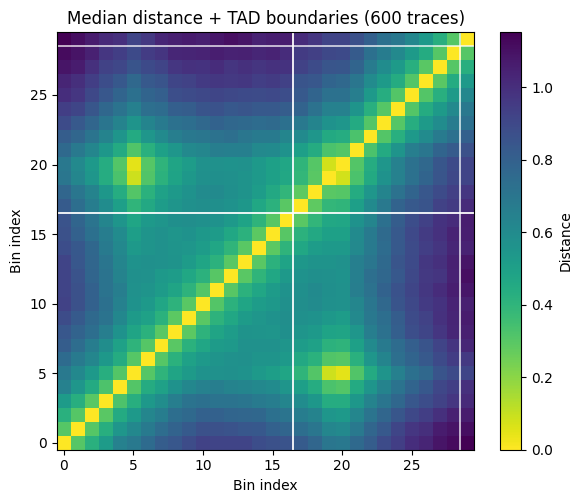

In [4]:
df = cd.get_chrom(chrom).to_dataframe()
dmat, bin_ids, n_traces = mean_distance_matrix(df, chrom=chrom)
B = len(bin_ids)
mid_bp = np.array([(s + e) * 0.5 for (s, e) in bin_ids])

fig = plot_distance_matrix(dmat, title=f'Median distance + TAD boundaries ({n_traces} traces)')
ax = fig.axes[0]

# Draw level-1 TAD boundaries as white lines
top_level = tads[tads['level'] == tads['level'].min()]
for _, row in top_level.iterrows():
    # Find the bin index of each TAD end; draw a line there
    for edge_bp in (row['start'], row['end']):
        # Closest bin midpoint
        k = int(np.argmin(np.abs(mid_bp - edge_bp)))
        if 0 < k < B:
            ax.axhline(k - 0.5, color='white', lw=1.2, alpha=0.8)
            ax.axvline(k - 0.5, color='white', lw=1.2, alpha=0.8)
plt.show()


## Hierarchy

When `hierarchical=True`, TADs are emitted at multiple levels of strictness.  Level 1 keeps only the most confident boundaries (coarse TADs); deeper levels include progressively weaker ones, producing nested structure.


TADs per level:
level
1    2
2    4
3    6
dtype: int64


/var/folders/tq/285915z105g568z0ss3ll7_w0000gn/T/ipykernel_45157/4149963415.py:12: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.axvspan(r['start'], r['end'], alpha=0.25, color='tab:blue',


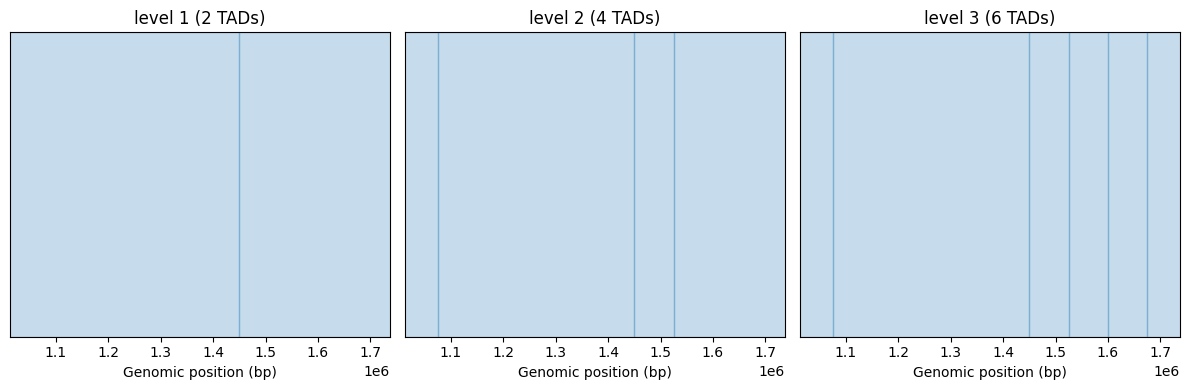

In [5]:
print('TADs per level:')
print(tads.groupby('level').size())

fig, axes = plt.subplots(1, min(3, tads['level'].max()), figsize=(12, 4), sharey=True)
if not hasattr(axes, '__len__'):
    axes = [axes]
for i, lv in enumerate(sorted(tads['level'].unique())[:3]):
    ax = axes[i]
    sub = tads[tads['level'] == lv]
    ax.set_title(f'level {lv} ({len(sub)} TADs)')
    for _, r in sub.iterrows():
        ax.axvspan(r['start'], r['end'], alpha=0.25, color='tab:blue',
                   edgecolor='navy', linewidth=1)
    ax.set_xlim(mid_bp.min(), mid_bp.max())
    ax.set_xlabel('Genomic position (bp)')
    ax.set_yticks([])
plt.tight_layout()
plt.show()


## Notes

- The variance-normalisation preprocessing is shared with
  :func:`uchrom.strc.loop.call_loops_axiswise_f` — you only pay for it
  once per chromosome if you cache.
- For a "flat" TAD partition set ``hierarchical=False`` or just use
  ``level == 1``.
- This caller complements the classical directionality-index method
  available in :func:`uchrom.strc.tad.get_domains`; they agree on
  strong TADs and disagree on boundary-marginal ones.
